# CreditLens: explainable credit risk for MSMEs without a credit score
**HackConquest 2026 · PS 12 · Predictive Credit Risk Analytics for MSMEs**

This notebook is the working proof-of-concept. It runs top to bottom and produces every number and chart you need for the PPT and the demo:

1. Synthetic India MSME data (GST, UPI, utility, invoice signals) with realistic relationships
2. Traditional (bureau-score) model vs CreditLens (alternative data) model
3. 6-month cash-flow forecasting and forecast debt-service coverage
4. Explainability: plain-language reason codes for every borrower
5. Borrower risk segmentation
6. Fairness and bias audit, with a mitigation and before/after numbers
7. Scenario simulator (rate hike, demand slowdown, sector shock)
8. Optional validation on real US small-business loan data (SBA) if you download the file
9. Export of model and data for the Streamlit dashboard

**Only numpy, pandas, scikit-learn and matplotlib are required.** If `xgboost` and `shap` are installed the notebook automatically uses them (SHAP plots); otherwise it falls back to scikit-learn boosting and a built-in explanation method.

**Honesty note for judges:** the India alternative-data features are synthetic (real GST/UPI/bank data is not public). Relationships are calibrated to plausible patterns, and the pipeline is built to accept real data.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("artifacts", exist_ok=True)

try:
    import xgboost as xgb
    HAS_XGB = True
except Exception:
    HAS_XGB = False
try:
    import shap
    HAS_SHAP = True
except Exception:
    HAS_SHAP = False
print("xgboost available:", HAS_XGB, "| shap available:", HAS_SHAP)

xgboost available: True | shap available: True


## 1. Data: synthetic India MSME portfolio
Each business has a hidden "true quality". The observed signals (GST on-time rate, UPI volatility, utility delays, receivable days, customer concentration, bounced payments) are noisy views of it. **Rural and Tier-2 businesses have noisier data**, which is realistic and gives the fairness audit something real to find.
Default is drawn from a logistic model, calibrated to about 10% portfolio default rate.

In [2]:
SECTORS = ["Retail", "Manufacturing", "Services", "Agri-processing", "Logistics"]
SECTOR_P = [0.32, 0.25, 0.22, 0.11, 0.10]
SECTOR_RISK = {"Retail": 0.0, "Manufacturing": 0.15, "Services": -0.10, "Agri-processing": 0.25, "Logistics": 0.10}
TARGET_DEFAULT_RATE = 0.10

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def add_derived(d):
    d["dti"] = d["existing_debt_lakh"] / d["annual_turnover_lakh"]
    d["loan_to_turnover"] = d["loan_amount_lakh"] / d["annual_turnover_lakh"]
    return d

def gen_msme(n=5000, seed=SEED):
    r = np.random.default_rng(seed)
    d = pd.DataFrame({"msme_id": [f"M{i:05d}" for i in range(n)]})
    d["sector"] = r.choice(SECTORS, n, p=SECTOR_P)
    d["region_type"] = r.choice(["Metro", "Tier-2", "Rural"], n, p=[0.30, 0.40, 0.30])
    d["size_band"] = r.choice(["Micro", "Small", "Medium"], n, p=[0.60, 0.30, 0.10])
    d["owner_gender"] = r.choice(["Female", "Male"], n, p=[0.22, 0.78])
    d["business_age"] = np.clip(r.gamma(2.5, 2.4, n), 0.5, 30).round(1)

    q = r.normal(0, 1, n)  # hidden business quality
    nm = d["region_type"].map({"Metro": 1.0, "Tier-2": 1.2, "Rural": 1.6}).values  # data noise by region
    scale = d["size_band"].map({"Micro": 1, "Small": 4, "Medium": 15}).values

    turnover = r.lognormal(np.log(25), 0.6, n) * scale
    d["annual_turnover_lakh"] = turnover.round(1)
    upi_share = r.uniform(0.4, 0.9, n)
    d["upi_share"] = upi_share.round(2)
    d["upi_inflow_monthly_lakh"] = (turnover / 12 * upi_share).round(2)
    d["gst_on_time_pct"] = np.clip(0.78 + 0.10 * q + r.normal(0, 0.07 * nm), 0.2, 1.0)
    d["upi_volatility"] = np.clip(0.32 - 0.07 * q + r.normal(0, 0.08 * nm), 0.05, 1.0)
    d["utility_delay_days"] = np.clip(5 - 2.5 * q + r.normal(0, 3 * nm), 0, 60)
    d["receivable_days"] = np.clip(45 - 7 * q + r.normal(0, 10 * nm), 5, 150)
    d["customer_concentration"] = np.clip(0.40 - 0.07 * q + r.normal(0, 0.12 * nm), 0.05, 0.95)
    d["bounced_payments"] = r.poisson(np.clip(1.0 - 0.5 * q, 0.05, None))
    d["turnover_growth"] = 0.06 + 0.04 * q + r.normal(0, 0.08 * nm)
    d["existing_debt_lakh"] = (turnover * np.clip(0.30 - 0.05 * q + r.normal(0, 0.12, n), 0.0, 1.5)).round(1)
    d["loan_amount_lakh"] = (turnover * r.uniform(0.10, 0.50, n)).round(1)
    d["interest_rate"] = np.clip(r.normal(0.125, 0.025, n), 0.08, 0.20)
    d["op_margin"] = np.clip(0.14 + 0.03 * q + r.normal(0, 0.03, n), 0.03, 0.35)

    # thin-file: many micro / rural businesses have no bureau score at all
    p_missing = np.clip(0.25 + 0.20 * (d["size_band"] == "Micro") + 0.10 * (d["region_type"] == "Rural"), 0, 0.8)
    bureau = np.clip(660 + 55 * q + r.normal(0, 55, n), 300, 900).round()
    bureau[r.random(n) < p_missing] = np.nan
    d["bureau_score"] = bureau
    d = add_derived(d)

    z = (2.5 * (0.78 - d["gst_on_time_pct"]) + 1.5 * (d["upi_volatility"] - 0.32)
         + 0.04 * d["utility_delay_days"] + 0.012 * (d["receivable_days"] - 45)
         + 1.5 * (d["customer_concentration"] - 0.40) + 0.20 * d["bounced_payments"]
         - 2.0 * (d["turnover_growth"] - 0.06) + 1.2 * d["dti"]
         + d["sector"].map(SECTOR_RISK) + 12 * (d["interest_rate"] - 0.125)
         - 0.03 * d["business_age"] - 0.7 * q + r.normal(0, 1.0, n)).values
    lo, hi = -12.0, 6.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if sigmoid(z + mid).mean() > TARGET_DEFAULT_RATE:
            hi = mid
        else:
            lo = mid
    d["default"] = (r.random(n) < sigmoid(z + mid)).astype(int)
    return d

df = gen_msme()
print(df.shape, "| default rate:", round(df["default"].mean() * 100, 1), "% | no bureau score:", round(df["bureau_score"].isna().mean() * 100, 1), "%")
df.head()

(5000, 24) | default rate: 10.2 % | no bureau score: 39.5 %


,msme_id,sector,region_type,size_band,owner_gender,business_age,annual_turnover_lakh,upi_share,upi_inflow_monthly_lakh,gst_on_time_pct,upi_volatility,utility_delay_days,receivable_days,customer_concentration,bounced_payments,turnover_growth,existing_debt_lakh,loan_amount_lakh,interest_rate,op_margin,bureau_score,dti,loan_to_turnover,default
0,M00000,Services,Metro,Small,Male,7.0,58.0,0.69,3.33,0.762867,0.328316,5.066399,48.712473,0.230710,0,0.231575,14.5,20.3,0.154414,0.172791,NaN,0.250000,0.350000,0
1,M00001,Manufacturing,Tier-2,Small,Female,16.3,37.3,0.73,2.28,0.920598,0.261970,7.345262,7.841527,0.489956,0,0.108262,17.3,12.4,0.108349,0.161636,639.0,0.463807,0.332440,0
2,M00002,Agri-processing,Rural,Micro,Male,5.7,19.4,0.61,0.99,0.915403,0.081620,0.000000,55.399893,0.233704,0,0.150690,0.3,7.5,0.142634,0.242368,NaN,0.015464,0.386598,0
3,M00003,Services,Metro,Micro,Male,7.6,29.6,0.73,1.79,0.881035,0.340970,6.599286,46.434551,0.277810,0,-0.019223,4.4,5.4,0.141854,0.180761,NaN,0.148649,0.182432,0
4,M00004,Retail,Metro,Micro,Male,1.4,32.1,0.48,1.30,0.876455,0.328569,5.174292,47.011642,0.300459,0,0.078031,10.3,14.6,0.150927,0.185803,NaN,0.320872,0.454829,0


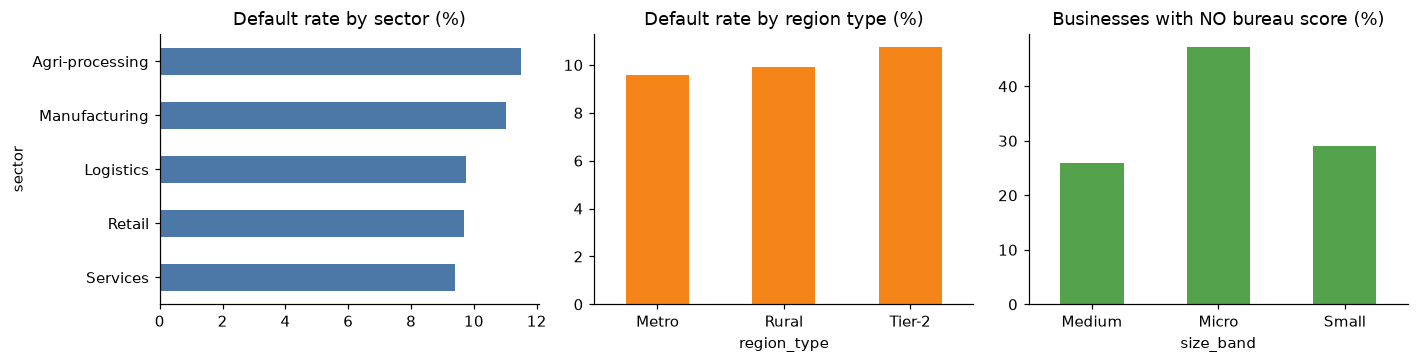

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
df.groupby("sector")["default"].mean().mul(100).sort_values().plot.barh(ax=ax[0], color="#4C78A8")
ax[0].set_title("Default rate by sector (%)")
df.groupby("region_type")["default"].mean().mul(100).plot.bar(ax=ax[1], color="#F58518", rot=0)
ax[1].set_title("Default rate by region type (%)")
(df["bureau_score"].isna().groupby(df["size_band"]).mean().mul(100)).plot.bar(ax=ax[2], color="#54A24B", rot=0)
ax[2].set_title("Businesses with NO bureau score (%)")
plt.tight_layout(); plt.show()

## 2. Traditional model vs CreditLens
* **Traditional lender view:** bureau score (plus age, leverage). No score means decline.
* **CreditLens:** bureau score if present **plus** alternative data (GST, UPI, utilities, invoices).

The key proof for judges: on **thin-file** businesses (no bureau score) the traditional model is nearly blind, while CreditLens still separates good from bad borrowers.

In [4]:
ALT = ["gst_on_time_pct", "upi_inflow_monthly_lakh", "upi_volatility", "utility_delay_days",
       "receivable_days", "customer_concentration", "bounced_payments", "turnover_growth"]
NUM = ["business_age", "annual_turnover_lakh", "dti", "loan_to_turnover", "interest_rate"] + ALT

def build_X(d):
    X = d[NUM].copy()
    X["bureau_score"] = d["bureau_score"]
    X["bureau_missing"] = d["bureau_score"].isna().astype(int)
    for s in SECTORS:
        X[f"sector_{s}"] = (d["sector"] == s).astype(int)
    return X.astype(float)

def build_trad(d, med):
    return pd.DataFrame({"bureau_score": d["bureau_score"].fillna(med),
                         "bureau_missing": d["bureau_score"].isna().astype(int),
                         "business_age": d["business_age"], "dti": d["dti"],
                         "loan_to_turnover": d["loan_to_turnover"]})

# Business-logic (monotonic) constraints: more debt, higher rates, slower collections etc. can never LOWER predicted risk.
# This keeps the model sensible under stress scenarios and is easy to defend to regulators.
MONO = {"interest_rate": 1, "dti": 1, "loan_to_turnover": 1, "utility_delay_days": 1, "receivable_days": 1,
        "customer_concentration": 1, "bounced_payments": 1, "upi_volatility": 1,
        "gst_on_time_pct": -1, "turnover_growth": -1}

def make_model(cols):
    mono = [MONO.get(c, 0) for c in cols]
    if HAS_XGB:
        return xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                 eval_metric="logloss", random_state=SEED, monotone_constraints=tuple(mono))
    return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=250, random_state=SEED, monotonic_cst=mono)

def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

train, test = train_test_split(df, test_size=0.30, stratify=df["default"], random_state=SEED)
train, test = train.copy(), test.copy()

bureau_med = train["bureau_score"].median()
trad = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
trad.fit(build_trad(train, bureau_med), train["default"])
test["pd_trad"] = trad.predict_proba(build_trad(test, bureau_med))[:, 1]

X_train, X_test = build_X(train), build_X(test)
model = make_model(list(X_train.columns))
model.fit(X_train, train["default"])
test["pd"] = model.predict_proba(X_test)[:, 1]

def report(mask, name):
    y = test.loc[mask, "default"]
    return {"segment": name, "n": int(mask.sum()), "defaults": int(y.sum()),
            "AUC traditional": round(roc_auc_score(y, test.loc[mask, "pd_trad"]), 3),
            "AUC CreditLens": round(roc_auc_score(y, test.loc[mask, "pd"]), 3),
            "KS CreditLens": round(ks_stat(y, test.loc[mask, "pd"]), 3)}

thin = test["bureau_score"].isna()
res = pd.DataFrame([report(pd.Series(True, index=test.index), "All businesses"),
                    report(~thin, "Has bureau score"), report(thin, "Thin-file (no score)")])
print("PR-AUC  traditional:", round(average_precision_score(test["default"], test["pd_trad"]), 3),
      "| CreditLens:", round(average_precision_score(test["default"], test["pd"]), 3))
res

PR-AUC  traditional: 0.222 | CreditLens: 0.35


,segment,n,defaults,AUC traditional,AUC CreditLens,KS CreditLens
0,All businesses,1500,152,0.713,0.798,0.469
1,Has bureau score,912,85,0.720,0.777,0.433
2,Thin-file (no score),588,67,0.725,0.824,0.530


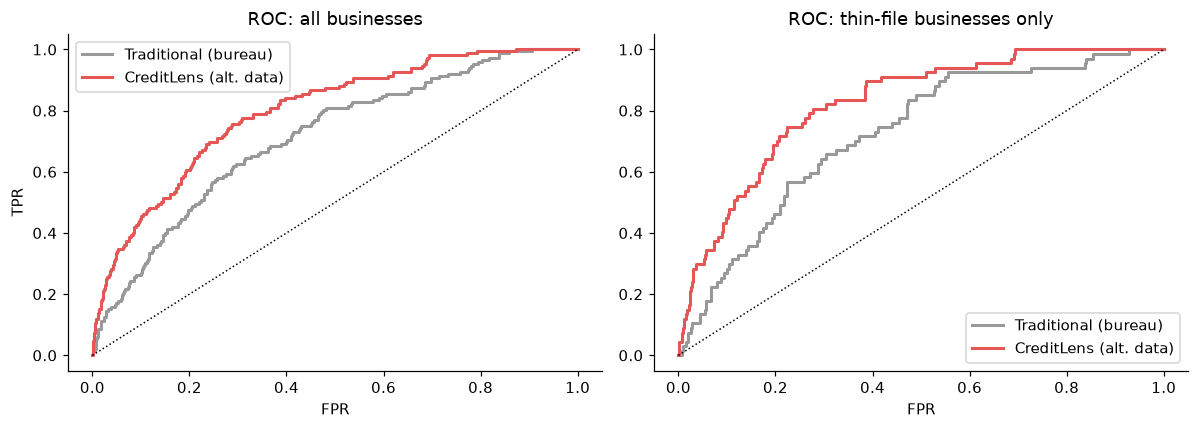

{'trad_approval_rate': 34.7, 'creditlens_approval_rate': 76.8, 'bad_rate_among_approved_pct': 5.4, 'good_thin_file_approved_trad_pct': 0.0, 'good_thin_file_approved_creditlens_pct': 82.0}
At the same default rate among approved loans (5.4%), CreditLens approves 76.8% of applicants vs 34.7% for the traditional policy.
Creditworthy thin-file businesses approved: 0.0% -> 82.0%
Note: the traditional policy here is a stylised rule (decline if bureau score < 650 or missing). Quote the AUC comparison as the primary evidence and this as an illustration.


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, col, c in [("Traditional (bureau)", "pd_trad", "#999999"), ("CreditLens (alt. data)", "pd", "#E45756")]:
    fpr, tpr, _ = roc_curve(test["default"], test[col]); ax[0].plot(fpr, tpr, label=name, color=c, lw=2)
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set_title("ROC: all businesses"); ax[0].legend(); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
for name, col, c in [("Traditional (bureau)", "pd_trad", "#999999"), ("CreditLens (alt. data)", "pd", "#E45756")]:
    fpr, tpr, _ = roc_curve(test.loc[thin, "default"], test.loc[thin, col]); ax[1].plot(fpr, tpr, label=name, color=c, lw=2)
ax[1].plot([0, 1], [0, 1], "k:", lw=1); ax[1].set_title("ROC: thin-file businesses only"); ax[1].legend(); ax[1].set_xlabel("FPR")
plt.tight_layout(); plt.show()

# Headline metric: financial inclusion at the SAME risk level
trad_approved = test["bureau_score"].notna() & (test["bureau_score"] >= 650)
b0 = test.loc[trad_approved, "default"].mean()
order = test.sort_values("pd")
cum_bad = order["default"].cumsum().values / np.arange(1, len(order) + 1)
k = int(np.where(cum_bad <= b0)[0].max() + 1)
cl_approved = pd.Series(False, index=test.index); cl_approved.loc[order.index[:k]] = True
good_thin = thin & (test["default"] == 0)
HEADLINE = {
    "trad_approval_rate": round(float(trad_approved.mean() * 100), 1),
    "creditlens_approval_rate": round(float(cl_approved.mean() * 100), 1),
    "bad_rate_among_approved_pct": round(float(b0 * 100), 1),
    "good_thin_file_approved_trad_pct": round(float((trad_approved & good_thin).sum() / good_thin.sum() * 100), 1),
    "good_thin_file_approved_creditlens_pct": round(float((cl_approved & good_thin).sum() / good_thin.sum() * 100), 1),
}
print(HEADLINE)
print(f"At the same default rate among approved loans ({HEADLINE['bad_rate_among_approved_pct']}%), "
      f"CreditLens approves {HEADLINE['creditlens_approval_rate']}% of applicants vs {HEADLINE['trad_approval_rate']}% for the traditional policy.")
print(f"Creditworthy thin-file businesses approved: {HEADLINE['good_thin_file_approved_trad_pct']}% -> {HEADLINE['good_thin_file_approved_creditlens_pct']}%")
print("Note: the traditional policy here is a stylised rule (decline if bureau score < 650 or missing). Quote the AUC comparison as the primary evidence and this as an illustration.")

## 3. Cash-flow forecasting (6 months ahead)
24 months of monthly revenue per business (festive-season peak, trend, volatility). We fit a shared seasonal profile plus a per-business trend on the first 18 months, forecast the last 6, and compare with a **seasonal-naive** baseline. The forecast also gives a **forecast debt-service coverage ratio (DSCR)**: forecast operating cash divided by the monthly instalment (60-month loan).

In [6]:
SEASON = np.array([0.92, 0.90, 1.02, 1.00, 0.98, 0.95, 0.93, 0.97, 1.05, 1.18, 1.12, 1.06])  # Jan..Dec, Oct-Nov festive peak
T, T_TRAIN = 24, 18
r = np.random.default_rng(SEED + 1)
months = pd.period_range("2024-01", periods=T, freq="M")
mo = months.month.values - 1
n = len(df)
trend = (1 + df["turnover_growth"].values[:, None] / 12) ** np.arange(T)[None, :]
noise = np.exp(r.normal(0, 1, (n, T)) * (df["upi_volatility"].values[:, None] * 0.35))
revenue = df["upi_inflow_monthly_lakh"].values[:, None] * trend * SEASON[mo][None, :] * noise   # lakh per month

# fit on first 18 months: log-revenue = a + b*t + shared seasonal index
Y = np.log(revenue[:, :T_TRAIN]); t = np.arange(T_TRAIN, dtype=float)
def linfit(Y, t):
    tm, Ym = t.mean(), Y.mean(axis=1, keepdims=True)
    b = ((t - tm) * (Y - Ym)).sum(axis=1, keepdims=True) / ((t - tm) ** 2).sum()
    return Ym - b * tm, b
a, b = linfit(Y, t)
resid = Y - (a + b * t[None, :])
s_idx = np.array([resid[:, mo[:T_TRAIN] == m].mean() for m in range(12)]); s_idx -= s_idx.mean()
a, b = linfit(Y - s_idx[mo[:T_TRAIN]][None, :], t)
tf = np.arange(T_TRAIN, T, dtype=float)
forecast = np.exp(a + b * tf[None, :] + s_idx[mo[T_TRAIN:]][None, :])
actual = revenue[:, T_TRAIN:]
naive = revenue[:, T_TRAIN - 12:T - 12]   # seasonal naive: same month last year

mape = lambda f: np.median(np.abs(f - actual) / actual, axis=1)
print(f"Median MAPE  CreditLens forecast: {np.median(mape(forecast)) * 100:.1f}%  |  seasonal-naive baseline: {np.median(mape(naive)) * 100:.1f}%")

emi = df["loan_amount_lakh"].values * (1 + df["interest_rate"].values * 5) / 60     # 60-month loan, simple-interest approximation
total_rev_fc = forecast / df["upi_share"].values[:, None]                          # UPI revenue -> total revenue
dscr = (total_rev_fc * df["op_margin"].values[:, None] / emi[:, None]).min(axis=1)
df["dscr_fc_min"] = dscr
test["dscr_fc_min"] = df.loc[test.index, "dscr_fc_min"]
print("Share of borrowers with forecast DSCR < 1.0 (cannot cover instalments in some month):", round((dscr < 1).mean() * 100, 1), "%")
print("Default rate  DSCR<1: %.1f%%  |  DSCR>=1: %.1f%%" % (df.loc[dscr < 1, "default"].mean() * 100, df.loc[dscr >= 1, "default"].mean() * 100))

Median MAPE  CreditLens forecast: 8.2%  |  seasonal-naive baseline: 13.5%
Share of borrowers with forecast DSCR < 1.0 (cannot cover instalments in some month): 23.9 %
Default rate  DSCR<1: 20.5%  |  DSCR>=1: 6.9%


## 4. Explainability and the borrower report
Every decision comes with **reason codes in plain language**. If `shap` and `xgboost` are installed we also draw the global SHAP chart. The reason codes themselves use an occlusion method that works with any model: how much would this borrower's risk change if this one feature were at the portfolio median?

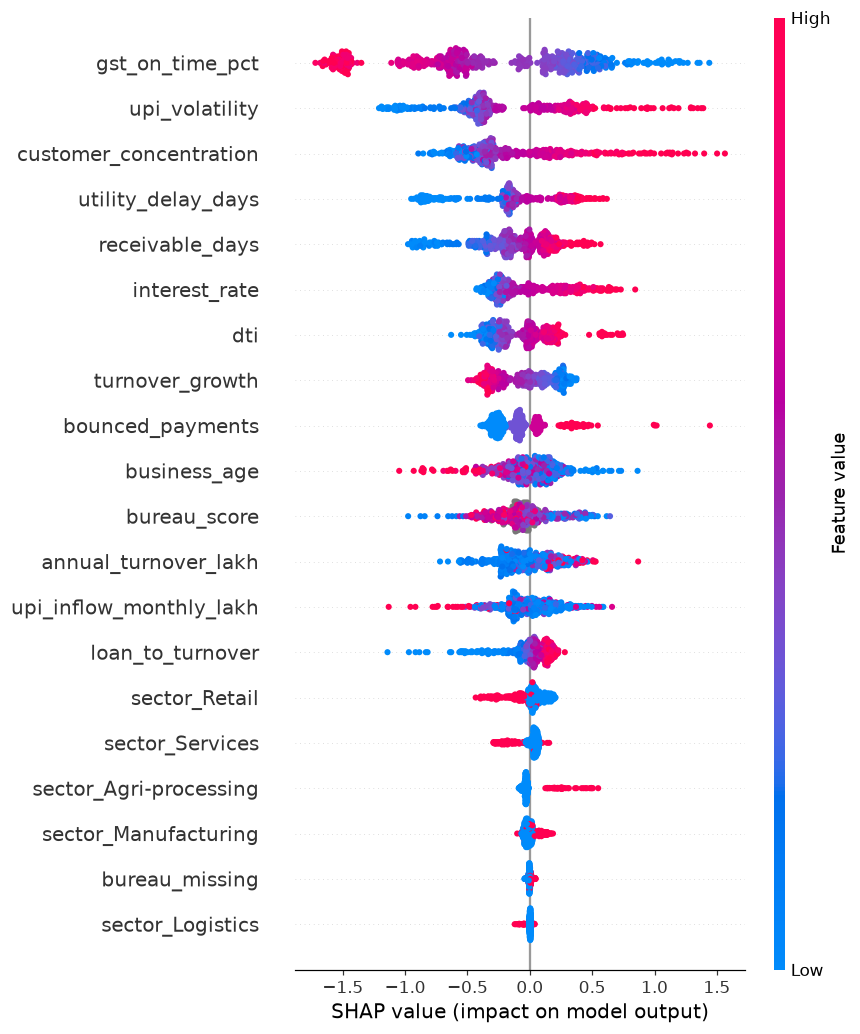

In [7]:
LABELS = {
    "business_age": "Business age", "annual_turnover_lakh": "Annual turnover", "dti": "Existing debt vs turnover",
    "loan_to_turnover": "Loan size vs turnover", "interest_rate": "Interest rate",
    "gst_on_time_pct": "GST on-time filing rate", "upi_inflow_monthly_lakh": "Monthly UPI inflow",
    "upi_volatility": "UPI cash-flow volatility", "utility_delay_days": "Utility bill payment delay",
    "receivable_days": "Customer payment collection time", "customer_concentration": "Dependence on top customers",
    "bounced_payments": "Bounced payments", "turnover_growth": "Turnover growth", "bureau_score": "Bureau score",
    "bureau_missing": "No bureau history",
}
FMT = {"gst_on_time_pct": lambda v: f"{v:.0%}", "upi_volatility": lambda v: f"{v:.2f}", "utility_delay_days": lambda v: f"{v:.0f} days",
       "receivable_days": lambda v: f"{v:.0f} days", "customer_concentration": lambda v: f"{v:.0%}", "bounced_payments": lambda v: f"{v:.0f}",
       "turnover_growth": lambda v: f"{v:+.0%}", "dti": lambda v: f"{v:.2f}x", "business_age": lambda v: f"{v:.1f} yrs",
       "loan_to_turnover": lambda v: f"{v:.2f}x", "interest_rate": lambda v: f"{v:.1%}", "annual_turnover_lakh": lambda v: f"Rs {v:.0f} lakh",
       "upi_inflow_monthly_lakh": lambda v: f"Rs {v:.1f} lakh", "bureau_score": lambda v: "none" if np.isnan(v) else f"{v:.0f}",
       "bureau_missing": lambda v: "yes" if v else "no"}
REF = X_train.median()

def reason_codes(x, top=4):
    x = x.astype(float)
    base = model.predict_proba(x.to_frame().T)[0, 1]
    occ = pd.DataFrame([x.values] * len(x), columns=x.index)
    for i, f in enumerate(x.index):
        occ.iloc[i, occ.columns.get_loc(f)] = REF[f]
    delta = base - model.predict_proba(occ)[:, 1]          # >0: this feature raises risk
    out = []
    for f, dlt in sorted(zip(x.index, delta), key=lambda z: -abs(z[1])):
        if f.startswith("sector_") or f == "bureau_missing" or f not in LABELS:
            continue
        if f == "bureau_score" and np.isnan(x[f]):
            continue      # thin-file: no bureau information to explain
        out.append(f"{LABELS[f]} ({FMT[f](x[f])}) {'raises' if dlt > 0 else 'lowers'} risk by {abs(dlt) * 100:.1f} pts")
        if len(out) == top:
            break
    return base, out

if HAS_XGB and HAS_SHAP:
    sv = shap.TreeExplainer(model).shap_values(X_test.iloc[:500])
    shap.summary_plot(sv, X_test.iloc[:500], show=False); plt.tight_layout(); plt.show()
else:
    from sklearn.inspection import permutation_importance
    pi = permutation_importance(model, X_test, test["default"], scoring="roc_auc", n_repeats=5, random_state=SEED)
    imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values().tail(12)
    imp.rename(lambda c: LABELS.get(c, c)).plot.barh(color="#4C78A8", figsize=(6.5, 4.2))
    plt.title("Global feature importance (permutation, drop in AUC)"); plt.tight_layout(); plt.show()

Borrower M02609 | Manufacturing | Rural | Small | requests Rs 19 lakh
Traditional policy : DECLINE (no bureau score)
CreditLens         : APPROVE   predicted default risk 1.2%   (portfolio average 9.2%)
Why:
  - Utility bill payment delay (0 days) lowers risk by 1.3 pts
  - Customer payment collection time (31 days) lowers risk by 0.7 pts
  - Annual turnover (Rs 126 lakh) raises risk by 0.6 pts
  - GST on-time filing rate (75%) raises risk by 0.5 pts
Forecast DSCR (worst month, next 6 mo): 6.37


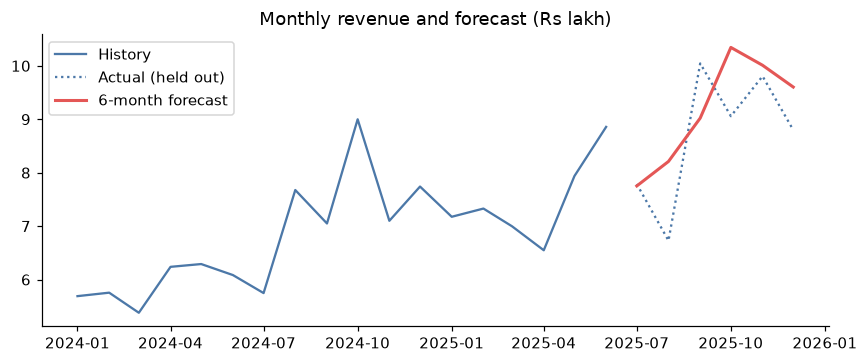

In [8]:
# Demo borrower: creditworthy thin-file business that the traditional policy would decline
cand = test[thin & (test["default"] == 0) & (test["pd"] < 0.06)].sort_values("pd")
i = cand.index[len(cand) // 2]
row = test.loc[i]
pd_i, reasons = reason_codes(build_X(test.loc[[i]]).iloc[0])
print(f"Borrower {row['msme_id']} | {row['sector']} | {row['region_type']} | {row['size_band']} | requests Rs {row['loan_amount_lakh']:.0f} lakh")
print("Traditional policy : DECLINE (no bureau score)")
print(f"CreditLens         : APPROVE   predicted default risk {pd_i:.1%}   (portfolio average {test['pd'].mean():.1%})")
print("Why:"); [print("  -", s) for s in reasons]
print(f"Forecast DSCR (worst month, next 6 mo): {row['dscr_fc_min']:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(months.to_timestamp()[:T_TRAIN], revenue[i, :T_TRAIN], color="#4C78A8", label="History")
ax.plot(months.to_timestamp()[T_TRAIN:], actual[i], color="#4C78A8", ls=":", label="Actual (held out)")
ax.plot(months.to_timestamp()[T_TRAIN:], forecast[i], color="#E45756", lw=2, label="6-month forecast")
ax.set_title("Monthly revenue and forecast (Rs lakh)"); ax.legend(); plt.tight_layout(); plt.show()

## 5. Risk segmentation
KMeans on risk and behaviour signals groups the portfolio into four tiers, named by average predicted risk.

                    businesses   avg PD %  actual default %  avg_loan_lakh  avg_gst_on_time
tier                                                                                       
Tier 1 - Healthy           247   0.200000               0.8           26.6              0.9
Tier 2 - Watch             491   1.400000               3.3           27.6              0.8
Tier 3 - Stressed          512   7.500000              11.3           24.3              0.7
Tier 4 - High risk         250  36.900002              30.4           33.8              0.6


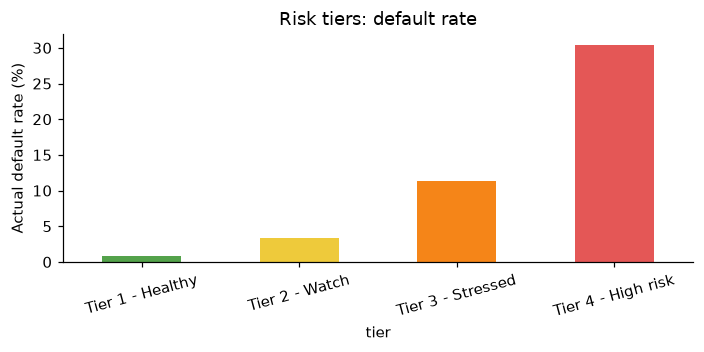

In [9]:
seg = pd.DataFrame({"risk_logit": np.log(test["pd"].clip(1e-4, 1 - 1e-4) / (1 - test["pd"].clip(1e-4, 1 - 1e-4))),
                    "dscr": test["dscr_fc_min"].clip(upper=test["dscr_fc_min"].quantile(0.99)),
                    "gst": test["gst_on_time_pct"]})
Z = StandardScaler().fit_transform(seg) * np.array([2.0, 1.0, 1.0])     # risk gets double weight
km = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(Z)
test["cluster"] = km.labels_
rank = test.groupby("cluster")["pd"].mean().sort_values().index.tolist()
names = dict(zip(rank, ["Tier 1 - Healthy", "Tier 2 - Watch", "Tier 3 - Stressed", "Tier 4 - High risk"]))
test["tier"] = test["cluster"].map(names)
tiers = (test.groupby("tier").agg(businesses=("msme_id", "count"), avg_predicted_pd=("pd", "mean"), actual_default_rate=("default", "mean"),
                                  avg_loan_lakh=("loan_amount_lakh", "mean"), avg_gst_on_time=("gst_on_time_pct", "mean"))
         .round(3))
display_tiers = tiers.copy(); display_tiers["avg_predicted_pd"] *= 100; display_tiers["actual_default_rate"] *= 100
print(display_tiers.round(1).rename(columns={"avg_predicted_pd": "avg PD %", "actual_default_rate": "actual default %"}))
fig, ax = plt.subplots(figsize=(6.5, 3.3))
tiers["actual_default_rate"].mul(100).plot.bar(ax=ax, color=["#54A24B", "#EECA3B", "#F58518", "#E45756"], rot=15)
ax.set_ylabel("Actual default rate (%)"); ax.set_title("Risk tiers: default rate"); plt.tight_layout(); plt.show()

## 6. Fairness and bias audit
The model never sees region type or gender. We still audit outcomes by group, because features can act as proxies (rural businesses have noisier data).
Approval rule: approve the safest 75% by predicted risk. Metrics per group:
* **Approval rate** and **disparate impact ratio** (lowest group rate divided by highest; 0.80 is the common rule-of-thumb floor)
* **Good-borrower approval rate** (equal opportunity): of businesses that would have repaid, how many were approved
* **Default rate among approved**

=== BEFORE mitigation (single global threshold) ===

region_type   disparate impact ratio = 0.93
               n  approval_rate  good_borrower_approval  default_rate_of_approved
region_type                                                                      
Metro        452          0.772                   0.801                     0.066
Rural        462          0.716                   0.767                     0.036
Tier-2       586          0.759                   0.808                     0.047

owner_gender   disparate impact ratio = 1.00
                 n  approval_rate  good_borrower_approval  default_rate_of_approved
owner_gender                                                                       
Female         326          0.748                   0.789                     0.037
Male          1174          0.750                   0.794                     0.053

size_band   disparate impact ratio = 0.91
             n  approval_rate  good_borrower_approval  default_rate_

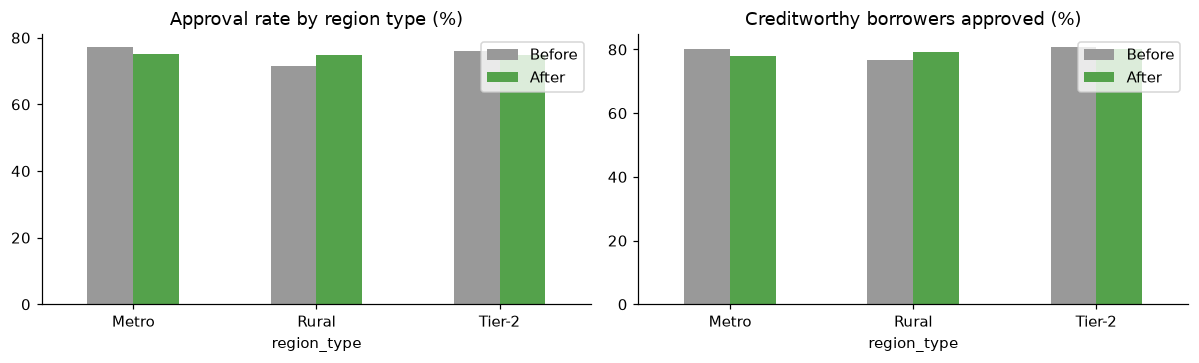

In [10]:
APPROVE_RATE = 0.75

def audit(d, approved, col):
    g = d.assign(approved=approved.astype(int))
    out = g.groupby(col).apply(lambda x: pd.Series({
        "n": len(x), "approval_rate": x["approved"].mean(),
        "good_borrower_approval": x.loc[x["default"] == 0, "approved"].mean(),
        "default_rate_of_approved": x.loc[x["approved"] == 1, "default"].mean()}))
    return out

def di_ratio(t):
    return t["approval_rate"].min() / t["approval_rate"].max()

thr = test["pd"].quantile(APPROVE_RATE)
approved_before = test["pd"] <= thr
print("=== BEFORE mitigation (single global threshold) ===")
for col in ["region_type", "owner_gender", "size_band"]:
    t = audit(test, approved_before, col)
    print(f"\n{col}   disparate impact ratio = {di_ratio(t):.2f}")
    print((t.assign(n=t["n"].astype(int)) .round(3)))

# Mitigation on region type: per-group thresholds that equalise approval rate
approved_after = pd.Series(False, index=test.index)
for gname, gidx in test.groupby("region_type").groups.items():
    approved_after.loc[gidx] = test.loc[gidx, "pd"] <= test.loc[gidx, "pd"].quantile(APPROVE_RATE)
t_before, t_after = audit(test, approved_before, "region_type"), audit(test, approved_after, "region_type")
print("\n=== AFTER mitigation (region-type thresholds equalising approval rate) ===")
print(t_after.assign(n=t_after["n"].astype(int)).round(3))
print(f"\nDisparate impact ratio: {di_ratio(t_before):.2f} -> {di_ratio(t_after):.2f}")
print(f"Default rate among approved (portfolio): {test.loc[approved_before, 'default'].mean():.2%} -> {test.loc[approved_after, 'default'].mean():.2%}   (the accuracy / fairness trade-off)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
pd.DataFrame({"Before": t_before["approval_rate"], "After": t_after["approval_rate"]}).mul(100).plot.bar(ax=ax[0], rot=0, color=["#999999", "#54A24B"])
ax[0].set_title("Approval rate by region type (%)")
pd.DataFrame({"Before": t_before["good_borrower_approval"], "After": t_after["good_borrower_approval"]}).mul(100).plot.bar(ax=ax[1], rot=0, color=["#999999", "#54A24B"])
ax[1].set_title("Creditworthy borrowers approved (%)")
plt.tight_layout(); plt.show()

## 7. Scenario simulator
Macro shocks are translated into changes in each business's features (turnover, UPI inflow, collections, GST compliance, utility delays, volatility, interest rate). Then the same model rescoring the whole portfolio gives the new expected default rate.

**Assumptions are illustrative.** In the next iteration, calibrate the shock-to-feature mappings using RBI / MoSPI history.

                           expected default rate %  loan-weighted %  <5% Healthy  5-10% Watch  10-20% Stressed  >20% High risk
scenario                                                                                                                      
Base case                                 9.200000             10.1         60.8         13.8             11.6            13.8
Rate hike +2pp                           10.900000             12.0         56.3         13.9             12.9            16.8
Demand slowdown -15%                     17.900000             19.3         38.3         17.1             14.9            29.7
Manufacturing shock -25%                 13.000000             14.4         54.3         13.2             12.0            20.5
Severe stress (all three)                25.299999             27.2         30.3         13.6             14.7            41.4


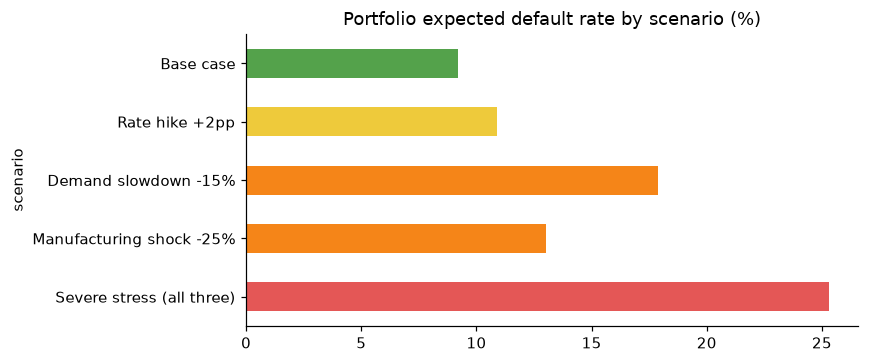

                 base %  manufacturing shock %
sector                                        
Agri-processing     9.5               9.500000
Logistics          10.6              10.600000
Manufacturing      10.2              24.700001
Retail              7.8               7.800000
Services            9.3               9.300000


In [11]:
def apply_scenario(d, rate_pp=0.0, demand_pct=0.0, sector=None, sector_pct=0.0):
    d = d.copy()
    s = np.full(len(d), demand_pct / 100.0)
    if sector:
        s = s + np.where(d["sector"] == sector, sector_pct / 100.0, 0.0)
    neg = -np.minimum(s, 0.0)                                   # size of the negative shock
    d["interest_rate"] = d["interest_rate"] + rate_pp / 100.0
    d["annual_turnover_lakh"] = d["annual_turnover_lakh"] * (1 + s)
    d["upi_inflow_monthly_lakh"] = d["upi_inflow_monthly_lakh"] * (1 + s)
    d["turnover_growth"] = d["turnover_growth"] + s
    d["receivable_days"] = d["receivable_days"] * (1 + 0.8 * neg)
    d["gst_on_time_pct"] = np.clip(d["gst_on_time_pct"] - 0.3 * neg, 0.2, 1.0)
    d["utility_delay_days"] = d["utility_delay_days"] * (1 + 1.5 * neg)
    d["upi_volatility"] = d["upi_volatility"] * (1 + np.abs(s))
    return add_derived(d)

BANDS = [0, 0.05, 0.10, 0.20, 1.0]; BAND_NAMES = ["<5% Healthy", "5-10% Watch", "10-20% Stressed", ">20% High risk"]
SCENARIOS = {
    "Base case": {},
    "Rate hike +2pp": {"rate_pp": 2},
    "Demand slowdown -15%": {"demand_pct": -15},
    "Manufacturing shock -25%": {"sector": "Manufacturing", "sector_pct": -25},
    "Severe stress (all three)": {"rate_pp": 2, "demand_pct": -15, "sector": "Manufacturing", "sector_pct": -25},
}
rows = []
for name, kw in SCENARIOS.items():
    p = model.predict_proba(build_X(apply_scenario(test, **kw)))[:, 1]
    band = pd.Series(pd.cut(p, BANDS, labels=BAND_NAMES, include_lowest=True)).value_counts(normalize=True).reindex(BAND_NAMES) * 100
    rows.append({"scenario": name, "expected default rate %": p.mean() * 100,
                 "loan-weighted %": np.average(p, weights=test["loan_amount_lakh"]) * 100, **band.round(1).to_dict()})
scen = pd.DataFrame(rows).set_index("scenario").round(1)
print(scen)
fig, ax = plt.subplots(figsize=(8, 3.4))
scen["expected default rate %"].plot.barh(ax=ax, color=["#54A24B", "#EECA3B", "#F58518", "#F58518", "#E45756"])
ax.invert_yaxis(); ax.set_title("Portfolio expected default rate by scenario (%)"); plt.tight_layout(); plt.show()

# By-sector view for the manufacturing shock
base_p = model.predict_proba(build_X(test))[:, 1]
shock_p = model.predict_proba(build_X(apply_scenario(test, **SCENARIOS["Manufacturing shock -25%"])))[:, 1]
print(pd.DataFrame({"base %": pd.Series(base_p, index=test.index).groupby(test["sector"]).mean() * 100,
                    "manufacturing shock %": pd.Series(shock_p, index=test.index).groupby(test["sector"]).mean() * 100}).round(1))

## 8. Optional: validate on REAL small-business loan data (SBA)
Download the **SBA National** loan dataset from Kaggle ("Should this loan be approved or denied?", file `SBAnational.csv`) and put it next to this notebook. This cell then trains on real defaults (charged-off vs paid-in-full) and reports a real AUC. It needs no changes if the file has the standard column names. Skip if you don't have the file; nothing else depends on it.

In [12]:
SBA_PATH = "SBAnational.csv"
SBA_AUC = None
if os.path.exists(SBA_PATH):
    try:
        sba = pd.read_csv(SBA_PATH, low_memory=False)
        sba = sba[sba["MIS_Status"].isin(["P I F", "CHGOFF"])].copy()
        money = lambda s: pd.to_numeric(s.astype(str).str.replace(r"[\$,\s]", "", regex=True), errors="coerce")
        Xs = pd.DataFrame({"disbursed": money(sba["DisbursementGross"]), "guaranteed": money(sba["GrAppv"]), "term_months": sba["Term"],
                           "employees": sba["NoEmp"], "new_business": (sba["NewExist"] == 2).astype(int),
                           "urban": (sba["UrbanRural"] == 1).astype(int), "low_doc": (sba["LowDoc"] == "Y").astype(int),
                           "revolving": (sba["RevLineCr"] == "Y").astype(int),
                           "naics2": pd.to_numeric(sba["NAICS"].astype(str).str[:2], errors="coerce")})
        ys = (sba["MIS_Status"] == "CHGOFF").astype(int)
        Xa, Xb, ya, yb = train_test_split(Xs, ys, test_size=0.25, stratify=ys, random_state=SEED)
        m = HistGradientBoostingClassifier(max_depth=5, learning_rate=0.08, max_iter=200, random_state=SEED).fit(Xa, ya)
        SBA_AUC = roc_auc_score(yb, m.predict_proba(Xb)[:, 1])
        print(f"REAL DATA (SBA, {len(sba):,} loans, default rate {ys.mean():.1%}): hold-out AUC = {SBA_AUC:.3f}")
    except Exception as e:
        print("SBA validation skipped:", type(e).__name__, e)
else:
    print("SBAnational.csv not found - skipping real-data validation (optional).")

SBAnational.csv not found - skipping real-data validation (optional).


## 9. Export for the Streamlit dashboard and a summary for the PPT

In [13]:
import json, joblib
joblib.dump({"model": model, "features": list(X_train.columns), "ref_median": REF}, "artifacts/creditlens_model.joblib")
test.drop(columns=["cluster"]).to_csv("artifacts/portfolio_scored.csv", index=False)
df.to_csv("artifacts/msme_synthetic.csv", index=False)

SUMMARY = {
    "portfolio_size": int(len(df)), "default_rate_pct": round(df["default"].mean() * 100, 1),
    "thin_file_share_pct": round(df["bureau_score"].isna().mean() * 100, 1),
    "AUC_traditional": float(res.loc[0, "AUC traditional"]), "AUC_creditlens": float(res.loc[0, "AUC CreditLens"]),
    "AUC_thin_file_traditional": float(res.loc[2, "AUC traditional"]), "AUC_thin_file_creditlens": float(res.loc[2, "AUC CreditLens"]),
    **HEADLINE,
    "forecast_MAPE_pct": round(float(np.median(mape(forecast)) * 100), 1), "seasonal_naive_MAPE_pct": round(float(np.median(mape(naive)) * 100), 1),
    "disparate_impact_before": round(float(di_ratio(t_before)), 2), "disparate_impact_after": round(float(di_ratio(t_after)), 2),
    "severe_stress_default_rate_pct": float(scen.loc["Severe stress (all three)", "expected default rate %"]),
    "sba_real_data_auc": None if SBA_AUC is None else round(float(SBA_AUC), 3),
}
json.dump(SUMMARY, open("artifacts/summary.json", "w"), indent=2)
print(json.dumps(SUMMARY, indent=2))

{
  "portfolio_size": 5000,
  "default_rate_pct": 10.2,
  "thin_file_share_pct": 39.5,
  "AUC_traditional": 0.713,
  "AUC_creditlens": 0.798,
  "AUC_thin_file_traditional": 0.725,
  "AUC_thin_file_creditlens": 0.824,
  "trad_approval_rate": 34.7,
  "creditlens_approval_rate": 76.8,
  "bad_rate_among_approved_pct": 5.4,
  "good_thin_file_approved_trad_pct": 0.0,
  "good_thin_file_approved_creditlens_pct": 82.0,
  "forecast_MAPE_pct": 8.2,
  "seasonal_naive_MAPE_pct": 13.5,
  "disparate_impact_before": 0.93,
  "disparate_impact_after": 1.0,
  "severe_stress_default_rate_pct": 25.299999237060547,
  "sba_real_data_auc": null
}


## What to do next
1. Put the numbers from the summary above into the PPT (slides on model, explainability, fairness, scenarios).
2. Build the Streamlit app on top of `artifacts/` (borrower view, portfolio view, scenario sliders, fairness panel).
3. If you have time, download the SBA file and re-run section 8 so you can say "validated on real loan defaults".